In [13]:
import random
import numpy as np
import torch
import os

def seed_everything(seed=42025):
 random.seed(seed)
 os.environ['PYTHONHASHSEED'] = str(seed)
 np.random.seed(seed)
 torch.manual_seed(seed)
 torch.cuda.manual_seed(seed)
 torch.cuda.manual_seed_all(seed)
 torch.backends.cudnn.deterministic = True
 torch.backends.cudnn.benchmark = False

seed_everything(42025)

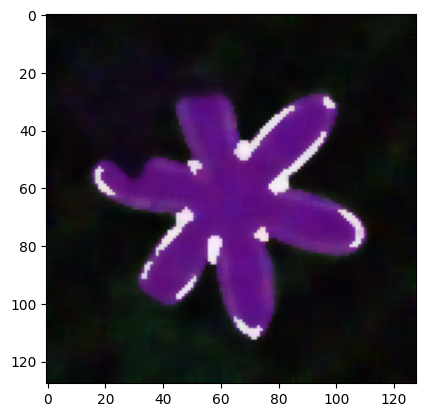

In [14]:
import cv2
import matplotlib.pyplot as plt

image1 = cv2.imread("dataset/test/test_001/0d14cf5dd6.jpg")
image1 = cv2.cvtColor(image1, cv2.COLOR_BGR2RGB)

def repair_image(img):
    img = cv2.medianBlur(img, 7)
    return img

image1 = repair_image(image1)

plt.imshow(image1)

In [34]:
import tqdm
from sklearn.decomposition import PCA
import torch
import torchvision.models as models
import torchvision.transforms as transforms

device = torch.device("cuda")
model = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.DEFAULT).to(device)
model.fc = torch.nn.Identity()
model.eval()

transform = transforms.ToTensor()

def get_features(image):
    img = transform(image).unsqueeze(0).to(device)
    with torch.no_grad():
        feat = model(img)
    return feat.squeeze().cpu().numpy()

def get_order(image_ids, X):
    decom = PCA(n_components=1)
    X = np.array(decom.fit_transform(X).squeeze())
    return image_ids[np.argsort(X)]

ids = []
answers = []
for folder in tqdm.tqdm(os.listdir('dataset/test')):
    ids.append(folder)

    image_ids = []
    X = []
    for image in os.listdir(f'dataset/test/{folder}'):
        path = f'dataset/test/{folder}/{image}'
        img = cv2.imread(path)
        if img is None:
            continue
        
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = repair_image(img)
        img = cv2.resize(img, (128, 128))
        
        X.append(get_features(img))
    
        image_ids.append(image)

    answer = get_order(np.array(image_ids), np.array(X))
    answers.append(answer)

answers[0]

100%|████████████████████████████████████████████████████████████████████████████████| 200/200 [01:02<00:00,  3.23it/s]


array(['17fd661aee.jpg', '05cfc96671.jpg', 'f935c01fa2.jpg',
       'e33afb59b2.jpg', '58460192d2.jpg', '60a2c197af.jpg',
       '2c6fa6e5da.jpg', 'a67d9a97e8.jpg', 'a550626819.jpg',
       '0d14cf5dd6.jpg', 'e0f930ebad.jpg', 'd041cfc0a7.jpg',
       '9b18c5a3da.jpg', '5807ceba81.jpg', '4566246b4a.jpg',
       '2c0d3006a7.jpg', 'd4d3f19c91.jpg', '0827813d28.jpg',
       '7b6cafc5f2.jpg', '124d3ba927.jpg', 'b383b43dae.jpg',
       '14f5264e58.jpg', '2f60c0fec1.jpg', 'd10f12f9e9.jpg',
       '18915da4b0.jpg', 'f1422f1329.jpg', '63bda6f461.jpg',
       '07825d1815.jpg', '78a5d90388.jpg', '01f8fd38f2.jpg',
       'a4fad54cc2.jpg', 'd7661560d0.jpg', '1a515640e0.jpg',
       '726d1978e7.jpg', 'a153fee182.jpg', 'bb67ea3ddb.jpg',
       '2ee0b537e9.jpg', '9596cfbc61.jpg', '27ece9eab8.jpg',
       '80bc4d5edf.jpg', '6f0f4eaa34.jpg', '064e37b5cb.jpg'], dtype='<U14')

In [35]:
preds = [' '.join(answer) for answer in answers]
preds[0]

'17fd661aee.jpg 05cfc96671.jpg f935c01fa2.jpg e33afb59b2.jpg 58460192d2.jpg 60a2c197af.jpg 2c6fa6e5da.jpg a67d9a97e8.jpg a550626819.jpg 0d14cf5dd6.jpg e0f930ebad.jpg d041cfc0a7.jpg 9b18c5a3da.jpg 5807ceba81.jpg 4566246b4a.jpg 2c0d3006a7.jpg d4d3f19c91.jpg 0827813d28.jpg 7b6cafc5f2.jpg 124d3ba927.jpg b383b43dae.jpg 14f5264e58.jpg 2f60c0fec1.jpg d10f12f9e9.jpg 18915da4b0.jpg f1422f1329.jpg 63bda6f461.jpg 07825d1815.jpg 78a5d90388.jpg 01f8fd38f2.jpg a4fad54cc2.jpg d7661560d0.jpg 1a515640e0.jpg 726d1978e7.jpg a153fee182.jpg bb67ea3ddb.jpg 2ee0b537e9.jpg 9596cfbc61.jpg 27ece9eab8.jpg 80bc4d5edf.jpg 6f0f4eaa34.jpg 064e37b5cb.jpg'

In [36]:
import pandas as pd

submission = pd.DataFrame({
    "subtaskID": 1,
    "datapointID": ids,
    "answer": preds
})

submission.head()

,subtaskID,datapointID,answer
0,1,test_001,17fd661aee.jpg 05cfc96671.jpg f935c01fa2.jpg e...
1,1,test_002,337f7fd5fa.jpg 8c0e4b4a65.jpg 4debaf1c00.jpg d...
2,1,test_003,b52a196b08.jpg ec06f7eb6f.jpg faf8fc3d79.jpg 7...
3,1,test_004,ac7d701ace.jpg e5d7351c9d.jpg 797358ea36.jpg d...
4,1,test_005,30c81bd984.jpg d4cf2d1880.jpg 986f25210a.jpg e...


In [37]:
submission.to_csv("submission.csv", index=False)

In [ ]:
#(pentru cine se uita pe filmare)
#m am dus sa mananc ceva brb